<a href="https://colab.research.google.com/github/Anas-Rabih/deep-learning-lab1-pytorch-mlp/blob/main/Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub skorch

import kagglehub
nyse_path  = kagglehub.dataset_download("dgawlik/nyse")
maint_path = kagglehub.dataset_download("shivamb/machine-predictive-maintenance-classification")
print(nyse_path, maint_path)

Using Colab cache for faster access to the 'nyse' dataset.
Using Colab cache for faster access to the 'machine-predictive-maintenance-classification' dataset.
/kaggle/input/nyse /kaggle/input/machine-predictive-maintenance-classification


In [2]:
import os

for p in [nyse_path, maint_path]:
    print(p)
    for f in os.listdir(p):
        print("   ", f, round(os.path.getsize(os.path.join(p, f)) / 1e6, 2), "MB")

/kaggle/input/nyse
    prices-split-adjusted.csv 52.7 MB
    fundamentals.csv 1.41 MB
    prices.csv 51.67 MB
    securities.csv 0.06 MB
/kaggle/input/machine-predictive-maintenance-classification
    predictive_maintenance.csv 0.53 MB


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(f"{nyse_path}/prices-split-adjusted.csv", parse_dates=["date"])

print(df.shape)
display(df.head())
df.info()
display(df.describe())

print("Missing values:\n", df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print("Symbols:", df.symbol.nunique(), "| from", df.date.min().date(), "to", df.date.max().date())

(851264, 7)


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB


,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294037760,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


Missing values:
 date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64
Duplicates: 0
Symbols: 501 | from 2010-01-04 to 2016-12-30


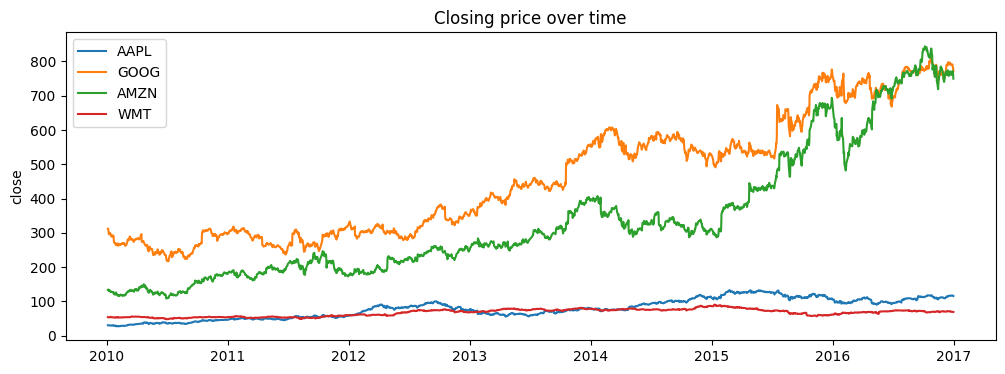

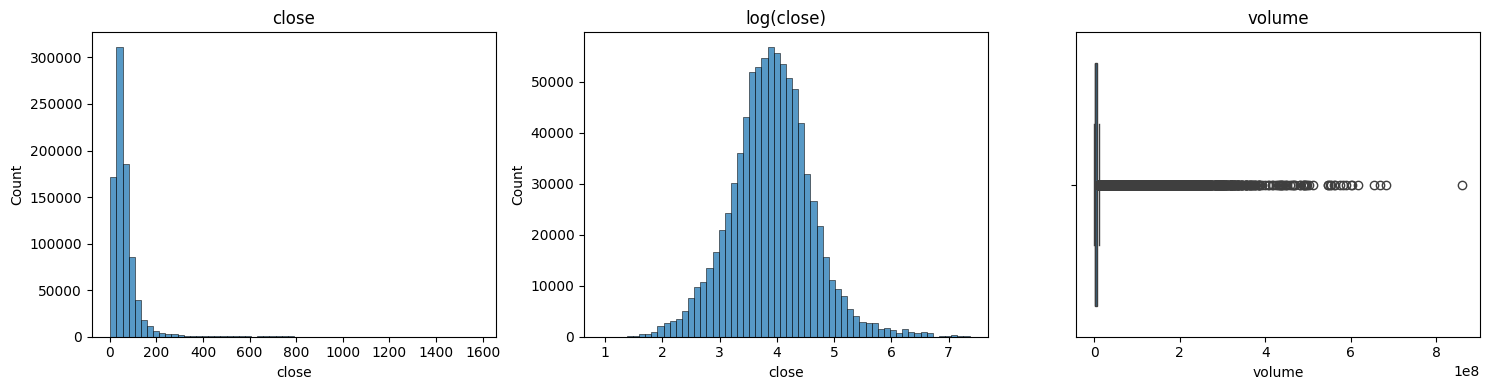

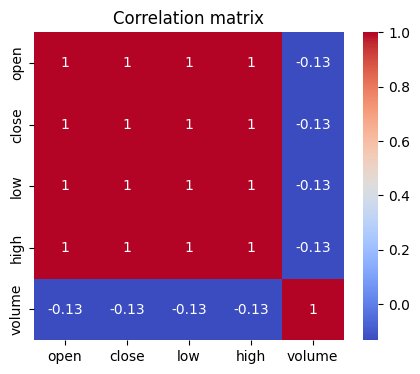

In [4]:
# 1) Price history of a few stocks
fig, ax = plt.subplots(figsize=(12, 4))
for s in ["AAPL", "GOOG", "AMZN", "WMT"]:
    d = df[df.symbol == s]
    ax.plot(d.date, d.close, label=s)
ax.set_title("Closing price over time"); ax.set_ylabel("close"); ax.legend()
plt.show()

# 2) Distributions (raw vs log) and outliers
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df.close, bins=60, ax=axs[0]).set_title("close")
sns.histplot(np.log1p(df.close), bins=60, ax=axs[1]).set_title("log(close)")
sns.boxplot(x=df.volume, ax=axs[2]).set_title("volume")
plt.tight_layout(); plt.show()

# 3) Correlations between numeric columns
plt.figure(figsize=(5, 4))
sns.heatmap(df[["open", "close", "low", "high", "volume"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation matrix"); plt.show()

In [5]:
# Sort, then build features per stock
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)

for c in ["open", "high", "low", "close"]:
    df[f"log_{c}"] = np.log(df[c])
df["log_volume"] = np.log1p(df["volume"])

for k in range(1, 5):
    df[f"log_close_lag{k}"] = df.groupby("symbol")["log_close"].shift(k)

# Target = next day's log close of the same stock
df["target"] = df.groupby("symbol")["log_close"].shift(-1)
df = df.dropna().reset_index(drop=True)

features = ["log_open", "log_high", "log_low", "log_close", "log_volume",
            "log_close_lag1", "log_close_lag2", "log_close_lag3", "log_close_lag4"]

# Chronological split
train_df = df[df.date <  "2016-01-01"]
test_df  = df[df.date >= "2016-01-01"]
print("train:", train_df.shape, "| test:", test_df.shape)

# Scaling: fit on TRAIN only (otherwise test information leaks)
from sklearn.preprocessing import StandardScaler
x_scaler, y_scaler = StandardScaler(), StandardScaler()

X_train = x_scaler.fit_transform(train_df[features])
X_test  = x_scaler.transform(test_df[features])
y_train = y_scaler.fit_transform(train_df[["target"]])
y_test  = y_scaler.transform(test_df[["target"]])

train: (723143, 17) | test: (125616, 17)


In [6]:
from sklearn.metrics import r2_score, mean_absolute_error

# Naive baseline: "tomorrow's close = today's close"
naive_pred = test_df["log_close"].values
print("Naive baseline  R2: %.5f | MAE (log): %.4f" %
      (r2_score(test_df["target"], naive_pred),
       mean_absolute_error(test_df["target"], naive_pred)))

Naive baseline  R2: 0.99934 | MAE (log): 0.0123


In [7]:
import torch
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

class StockDataset(Dataset):
    def __init__(self, X, y):
        self.X = X.astype("float32")
        self.y = y.astype("float32").reshape(-1, 1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return [self.X[idx], self.y[idx]]

train_ds = StockDataset(X_train, y_train)
test_ds  = StockDataset(X_test,  y_test)

# batch_size=512 instead of his 32: we have ~700k rows, 32 would be very slow
train_dl = DataLoader(train_ds, batch_size=512, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=2048, shuffle=False)
print(len(train_ds), len(test_ds))

Device: cpu
723143 125616


In [8]:
import torch.nn as nn
from torch.nn import Module, Linear, ReLU, MSELoss
from torch.nn.init import xavier_uniform_, kaiming_uniform_
from torch.optim import SGD
from sklearn.metrics import r2_score, mean_squared_error
from tqdm import tqdm

torch.manual_seed(42); np.random.seed(42)

class MLP(Module):
    def __init__(self, n_inputs, h1=64, h2=32):
        super().__init__()
        self.hidden1 = Linear(n_inputs, h1)
        kaiming_uniform_(self.hidden1.weight, nonlinearity="relu")
        self.act1 = ReLU()
        self.hidden2 = Linear(h1, h2)
        kaiming_uniform_(self.hidden2.weight, nonlinearity="relu")
        self.act2 = ReLU()
        self.hidden3 = Linear(h2, 1)          # regression: no activation on output
        xavier_uniform_(self.hidden3.weight)

    def forward(self, X):
        X = self.act1(self.hidden1(X))
        X = self.act2(self.hidden2(X))
        return self.hidden3(X)

def get_predictions(dl, model):
    model.eval()
    preds, actuals = [], []
    with torch.no_grad():
        for inputs, targets in dl:
            yhat = model(inputs.to(device))
            preds.append(yhat.cpu().numpy())
            actuals.append(targets.numpy())
    return np.vstack(preds), np.vstack(actuals)

def evaluate_model(dl, model):
    preds, actuals = get_predictions(dl, model)
    return mean_squared_error(actuals, preds), r2_score(actuals, preds)

def train_model(train_dl, test_dl, model, epochs=20, lr=0.01, momentum=0.9):
    model.to(device)
    criterion = MSELoss()
    optimizer = SGD(model.parameters(), lr=lr, momentum=momentum)
    history = {"train_loss": [], "test_loss": [], "train_r2": [], "test_r2": []}

    for epoch in tqdm(range(epochs), desc="Training Epochs"):
        model.train()
        for inputs, targets in train_dl:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()              # clear the gradients
            yhat = model(inputs)               # compute the model output
            loss = criterion(yhat, targets)    # calculate loss
            loss.backward()                    # credit assignment
            optimizer.step()                   # update model weights

        tr_loss, tr_r2 = evaluate_model(train_dl, model)
        te_loss, te_r2 = evaluate_model(test_dl, model)
        history["train_loss"].append(tr_loss); history["test_loss"].append(te_loss)
        history["train_r2"].append(tr_r2);     history["test_r2"].append(te_r2)
    return history

Training Epochs: 100%|██████████| 20/20 [03:33<00:00, 10.66s/it]


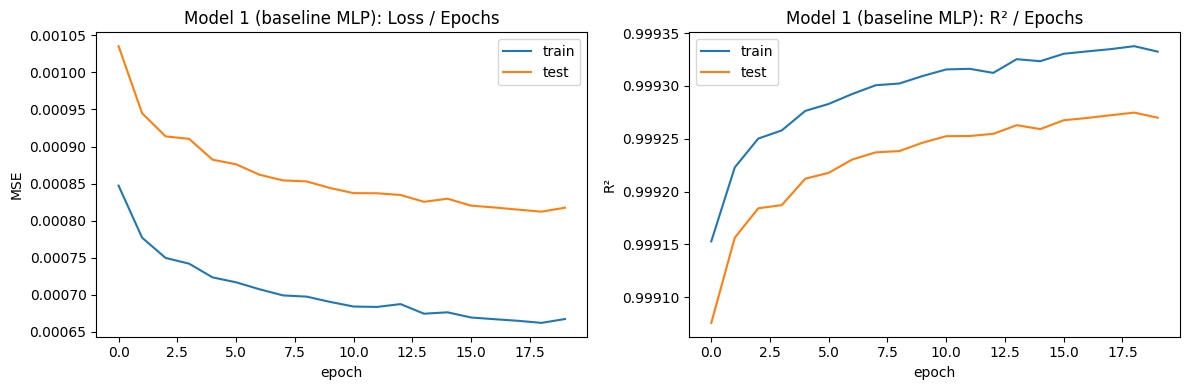

In [9]:
model1 = MLP(n_inputs=len(features))
hist1 = train_model(train_dl, test_dl, model1, epochs=20)

def plot_history(hist, title, metric="r2", label="R²"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title(f"{title}: Loss / Epochs"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("MSE"); ax[0].legend()
    ax[1].plot(hist[f"train_{metric}"], label="train"); ax[1].plot(hist[f"test_{metric}"], label="test")
    ax[1].set_title(f"{title}: {label} / Epochs"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel(label); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(hist1, "Model 1 (baseline MLP)")

In [10]:
def final_report(model, name):
    preds, actuals = get_predictions(test_dl, model)
    # back to log-price units, then compare
    p = y_scaler.inverse_transform(preds).ravel()
    a = y_scaler.inverse_transform(actuals).ravel()
    print(f"{name:25s} R2: {r2_score(a, p):.5f} | MAE (log): {mean_absolute_error(a, p):.4f}")

print("Naive baseline            R2: 0.99934 | MAE (log): 0.0123")
final_report(model1, "Model 1 (MLP)")

Naive baseline            R2: 0.99934 | MAE (log): 0.0123
Model 1 (MLP)             R2: 0.99927 | MAE (log): 0.0133


In [11]:
from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from torch.optim import Adam

# --- chronological train/validation split inside the training years ---
rng = np.random.RandomState(42)
is_val = (train_df.date >= "2015-01-01").values
idx_tr = rng.choice(np.where(~is_val)[0], 150_000, replace=False)
idx_va = rng.choice(np.where(is_val)[0],   40_000, replace=False)
idx = np.concatenate([idx_tr, idx_va])

X_gs = X_train[idx].astype("float32")
y_gs = y_train[idx].astype("float32")
cv = PredefinedSplit([-1] * len(idx_tr) + [0] * len(idx_va))   # -1 = always train, 0 = validation

net = NeuralNetRegressor(
    module=MLP,
    module__n_inputs=len(features),
    module__h2=32,
    batch_size=512,
    train_split=None,      # GridSearchCV handles validation
    device=device,
    verbose=0,
)

common = {
    "lr": [0.001, 0.01],
    "max_epochs": [10, 20],
    "module__h1": [32, 128],       # architecture
}
param_grid = [
    {"optimizer": [SGD],  "optimizer__momentum": [0.9], **common},
    {"optimizer": [Adam], **common},
]   # 2 x (2 x 2 x 2) = 16 combinations

gs = GridSearchCV(net, param_grid, cv=cv, scoring="neg_mean_squared_error",
                  refit=False, n_jobs=1, verbose=2)
gs.fit(X_gs, y_gs)

print("Best params:", gs.best_params_)
print("Best val MSE:", -gs.best_score_)

res = pd.DataFrame(gs.cv_results_)
res["optimizer"] = res["param_optimizer"].apply(lambda o: o.__name__)
display(res[["optimizer", "param_lr", "param_max_epochs", "param_module__h1", "mean_test_score"]]
        .sort_values("mean_test_score", ascending=False))

Fitting 1 folds for each of 16 candidates, totalling 16 fits
[CV] END lr=0.001, max_epochs=10, module__h1=32, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=  15.7s
[CV] END lr=0.001, max_epochs=10, module__h1=128, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=  13.4s
[CV] END lr=0.001, max_epochs=20, module__h1=32, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=  24.7s
[CV] END lr=0.001, max_epochs=20, module__h1=128, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=  26.8s
[CV] END lr=0.01, max_epochs=10, module__h1=32, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=  12.9s
[CV] END lr=0.01, max_epochs=10, module__h1=128, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=  13.4s
[CV] END lr=0.01, max_epochs=20, module__h1=32, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=  23.5s
[

,optimizer,param_lr,param_max_epochs,param_module__h1,mean_test_score
10,Adam,0.001,20,32,-0.000683
8,Adam,0.001,10,32,-0.000753
7,SGD,0.010,20,128,-0.000772
6,SGD,0.010,20,32,-0.000790
15,Adam,0.010,20,128,-0.000807
5,SGD,0.010,10,128,-0.000840
9,Adam,0.001,10,128,-0.000844
4,SGD,0.010,10,32,-0.000848
13,Adam,0.010,10,128,-0.000922
12,Adam,0.010,10,32,-0.001016


Training Epochs: 100%|██████████| 20/20 [03:35<00:00, 10.76s/it]


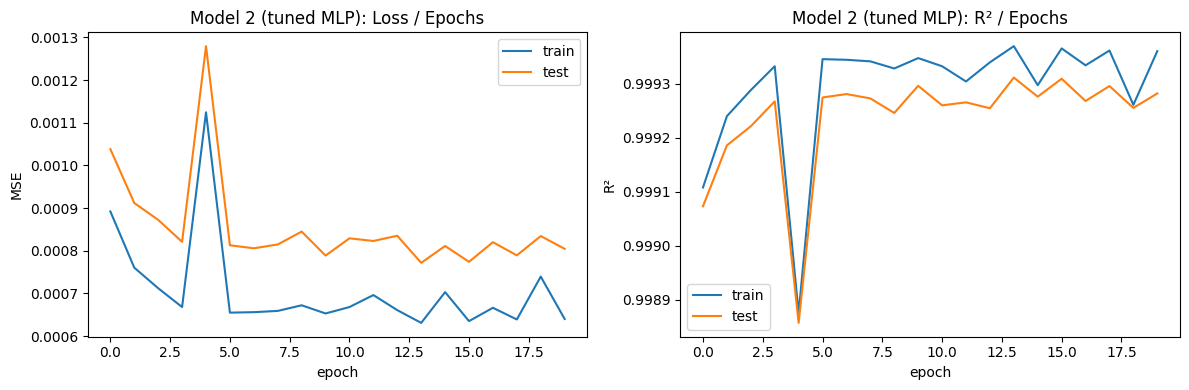

Naive baseline            R2: 0.99934 | MAE (log): 0.0123
Model 1 (MLP)             R2: 0.99927 | MAE (log): 0.0133
Model 2 (tuned MLP)       R2: 0.99928 | MAE (log): 0.0133


In [12]:
def train_model(train_dl, test_dl, model, epochs=20, optimizer_cls=SGD, lr=0.01, **opt_kwargs):
    model.to(device)
    criterion = MSELoss()
    optimizer = optimizer_cls(model.parameters(), lr=lr, **opt_kwargs)
    history = {"train_loss": [], "test_loss": [], "train_r2": [], "test_r2": []}

    for epoch in tqdm(range(epochs), desc="Training Epochs"):
        model.train()
        for inputs, targets in train_dl:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), targets)
            loss.backward()
            optimizer.step()

        tr_loss, tr_r2 = evaluate_model(train_dl, model)
        te_loss, te_r2 = evaluate_model(test_dl, model)
        history["train_loss"].append(tr_loss); history["test_loss"].append(te_loss)
        history["train_r2"].append(tr_r2);     history["test_r2"].append(te_r2)
    return history

bp = gs.best_params_
opt_kwargs = {"momentum": bp["optimizer__momentum"]} if bp["optimizer"] is SGD else {}

torch.manual_seed(42)
model2 = MLP(len(features), h1=bp["module__h1"], h2=32)
hist2 = train_model(train_dl, test_dl, model2, epochs=bp["max_epochs"],
                    optimizer_cls=bp["optimizer"], lr=bp["lr"], **opt_kwargs)

plot_history(hist2, "Model 2 (tuned MLP)")
print("Naive baseline            R2: 0.99934 | MAE (log): 0.0123")
final_report(model1, "Model 1 (MLP)")
final_report(model2, "Model 2 (tuned MLP)")

In [13]:
import copy
from torch.nn import Dropout

class MLPDrop(Module):
    def __init__(self, n_inputs, h1=32, h2=32, p=0.1):
        super().__init__()
        self.hidden1 = Linear(n_inputs, h1); kaiming_uniform_(self.hidden1.weight, nonlinearity="relu")
        self.act1 = ReLU(); self.drop1 = Dropout(p)
        self.hidden2 = Linear(h1, h2); kaiming_uniform_(self.hidden2.weight, nonlinearity="relu")
        self.act2 = ReLU(); self.drop2 = Dropout(p)
        self.hidden3 = Linear(h2, 1); xavier_uniform_(self.hidden3.weight)

    def forward(self, X):
        X = self.drop1(self.act1(self.hidden1(X)))
        X = self.drop2(self.act2(self.hidden2(X)))
        return self.hidden3(X)

def train_reg(train_dl, test_dl, model, epochs=20, optimizer_cls=Adam, lr=1e-3,
              weight_decay=0.0, l1=0.0, val_dl=None, patience=None, **opt_kwargs):
    model.to(device)
    criterion = MSELoss()
    optimizer = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay, **opt_kwargs)
    history = {"train_loss": [], "test_loss": [], "train_r2": [], "test_r2": []}
    best_val, best_state, wait = float("inf"), None, 0

    for epoch in tqdm(range(epochs), desc="Training Epochs"):
        model.train()
        for inputs, targets in train_dl:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), targets)
            if l1 > 0:   # L1 penalty on weights
                loss = loss + l1 * sum(p.abs().sum() for n, p in model.named_parameters() if "weight" in n)
            loss.backward()
            optimizer.step()

        tr_loss, tr_r2 = evaluate_model(train_dl, model)
        te_loss, te_r2 = evaluate_model(test_dl, model)
        history["train_loss"].append(tr_loss); history["test_loss"].append(te_loss)
        history["train_r2"].append(tr_r2);     history["test_r2"].append(te_r2)

        if val_dl is not None and patience:      # early stopping on a VALIDATION set
            v_loss, _ = evaluate_model(val_dl, model)
            if v_loss < best_val - 1e-7:
                best_val, best_state, wait = v_loss, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping at epoch {epoch+1}"); break
    if best_state is not None:
        model.load_state_dict(best_state)
    return history

def report_row(model, name):
    preds, actuals = get_predictions(test_dl, model)
    p = y_scaler.inverse_transform(preds).ravel(); a = y_scaler.inverse_transform(actuals).ravel()
    return {"model": name, "R2": r2_score(a, p), "MAE_log": mean_absolute_error(a, p)}

# Validation split for early stopping (chronological, inside the training years)
m_tr = (train_df.date < "2015-07-01").values
es_train_dl = DataLoader(StockDataset(X_train[m_tr],  y_train[m_tr]),  batch_size=512, shuffle=True)
val_dl      = DataLoader(StockDataset(X_train[~m_tr], y_train[~m_tr]), batch_size=2048)

Training Epochs:  12%|█▎        | 5/40 [00:55<06:29, 11.14s/it]

Early stopping at epoch 6


,model,R2,MAE_log
6,Naive baseline,0.999340,0.012300
1,L2 (wd=1e-5),0.999322,0.012542
2,L2 (wd=1e-4),0.999285,0.012994
3,L1 (1e-6),0.999286,0.013019
0,"Model 2 (tuned, no reg.)",0.999282,0.013256
5,Early stopping (patience=3),0.999212,0.013913
4,Dropout (p=0.1),0.986233,0.067961


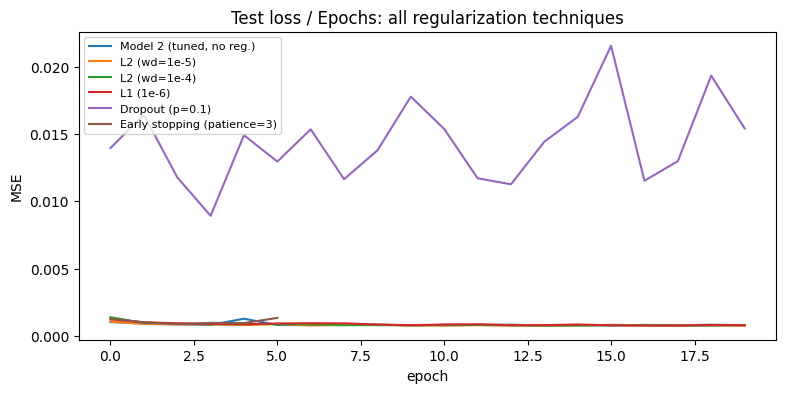

In [14]:
results = [report_row(model2, "Model 2 (tuned, no reg.)")]
histories = {"Model 2 (tuned, no reg.)": hist2}

def run(name, model, **kw):
    torch.manual_seed(42)
    h = train_reg(kw.pop("dl", train_dl), test_dl, model, **kw)
    histories[name] = h
    results.append(report_row(model, name))

run("L2 (wd=1e-5)", MLP(len(features), h1=32, h2=32), weight_decay=1e-5)
run("L2 (wd=1e-4)", MLP(len(features), h1=32, h2=32), weight_decay=1e-4)
run("L1 (1e-6)",    MLP(len(features), h1=32, h2=32), l1=1e-6)
run("Dropout (p=0.1)", MLPDrop(len(features), 32, 32, p=0.1))
run("Early stopping (patience=3)", MLP(len(features), h1=32, h2=32),
    dl=es_train_dl, epochs=40, val_dl=val_dl, patience=3)

comparison = pd.DataFrame(results)
comparison.loc[len(comparison)] = {"model": "Naive baseline", "R2": 0.99934, "MAE_log": 0.0123}
display(comparison.sort_values("MAE_log"))

# Overlay of test loss for all models
plt.figure(figsize=(9, 4))
for name, h in histories.items():
    plt.plot(h["test_loss"], label=name)
plt.title("Test loss / Epochs: all regularization techniques")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(fontsize=8); plt.show()

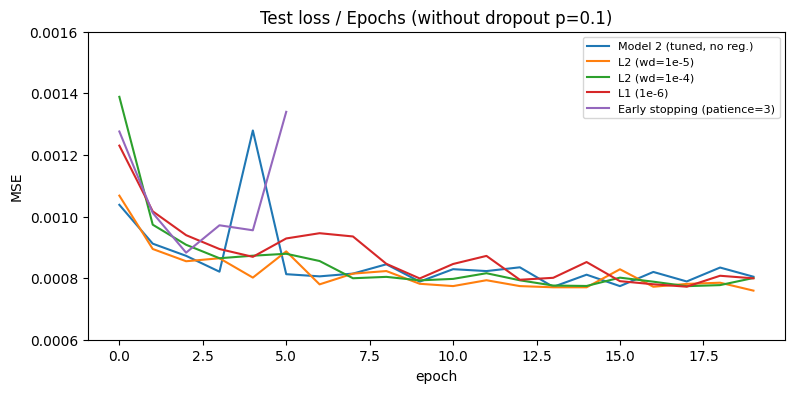

Training Epochs:  95%|█████████▌| 38/40 [06:43<00:21, 10.63s/it]

Early stopping at epoch 39


,model,R2,MAE_log
1,L2 (wd=1e-5),0.999322,0.012542
7,Early stopping (patience=7),0.999315,0.012675
2,L2 (wd=1e-4),0.999285,0.012994
3,L1 (1e-6),0.999286,0.013019
0,"Model 2 (tuned, no reg.)",0.999282,0.013256
5,Early stopping (patience=3),0.999212,0.013913
6,Dropout (p=0.02),0.998707,0.020265
4,Dropout (p=0.1),0.986233,0.067961


In [15]:
# Overlay without the failed dropout run
plt.figure(figsize=(9, 4))
for name, h in histories.items():
    if "Dropout" not in name:
        plt.plot(h["test_loss"], label=name)
plt.ylim(0.0006, 0.0016)
plt.title("Test loss / Epochs (without dropout p=0.1)")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(fontsize=8); plt.show()

# Retry: much weaker dropout, and early stopping with more patience
run("Dropout (p=0.02)", MLPDrop(len(features), 32, 32, p=0.02))
run("Early stopping (patience=7)", MLP(len(features), h1=32, h2=32),
    dl=es_train_dl, epochs=40, val_dl=val_dl, patience=7)

display(pd.DataFrame(results).sort_values("MAE_log"))

In [16]:
mdf = pd.read_csv(f"{maint_path}/predictive_maintenance.csv")
print(mdf.shape)
display(mdf.head())
mdf.info()
display(mdf.describe())

print("Missing:\n", mdf.isna().sum())
print("Duplicates:", mdf.duplicated().sum())

print("\nFailure Type counts:")
print(mdf["Failure Type"].value_counts())
print("\nTarget (binary) counts:")
print(mdf["Target"].value_counts())

# Consistency check between the binary Target and the Failure Type label
display(pd.crosstab(mdf["Failure Type"], mdf["Target"]))

(10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


Missing:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64
Duplicates: 0

Failure Type counts:
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64

Target (binary) counts:
Target
0    9661
1     339
Name: count, dtype: int64


Target,0,1
Failure Type,,
Heat Dissipation Failure,0,112
No Failure,9643,9
Overstrain Failure,0,78
Power Failure,0,95
Random Failures,18,0
Tool Wear Failure,0,45


In [17]:
cdf = mdf.copy()

bad_a = (cdf["Target"] == 1) & (cdf["Failure Type"] == "No Failure")        # 9 rows
bad_b = (cdf["Target"] == 0) & (cdf["Failure Type"] == "Random Failures")   # 18 rows
print("Contradictory rows:", bad_a.sum(), "+", bad_b.sum())
cdf = cdf[~(bad_a | bad_b)].reset_index(drop=True)

# Drop identifiers and the leaking binary Target, rename columns
cdf = cdf.drop(columns=["UDI", "Product ID", "Target"])
cdf.columns = ["Type", "air_temp", "proc_temp", "rpm", "torque", "tool_wear", "failure"]

print(cdf.shape)
print(cdf["failure"].value_counts())
display(cdf.describe())

Contradictory rows: 9 + 18
(9973, 7)
failure
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Name: count, dtype: int64


,air_temp,proc_temp,rpm,torque,tool_wear
count,9973.000000,9973.000000,9973.000000,9973.000000,9973.000000
mean,300.003259,310.004031,1538.893212,39.978993,107.921087
std,2.000548,1.483692,179.412171,9.966805,63.649152
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.700000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


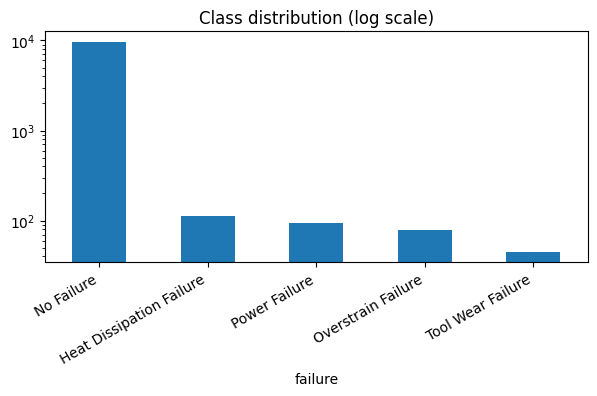

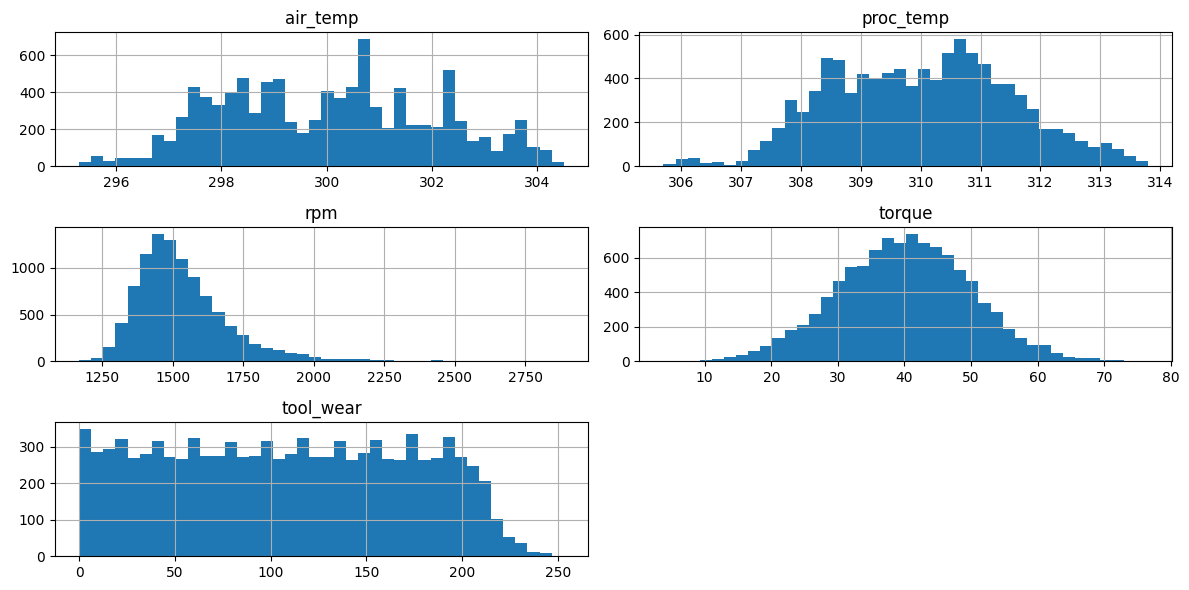

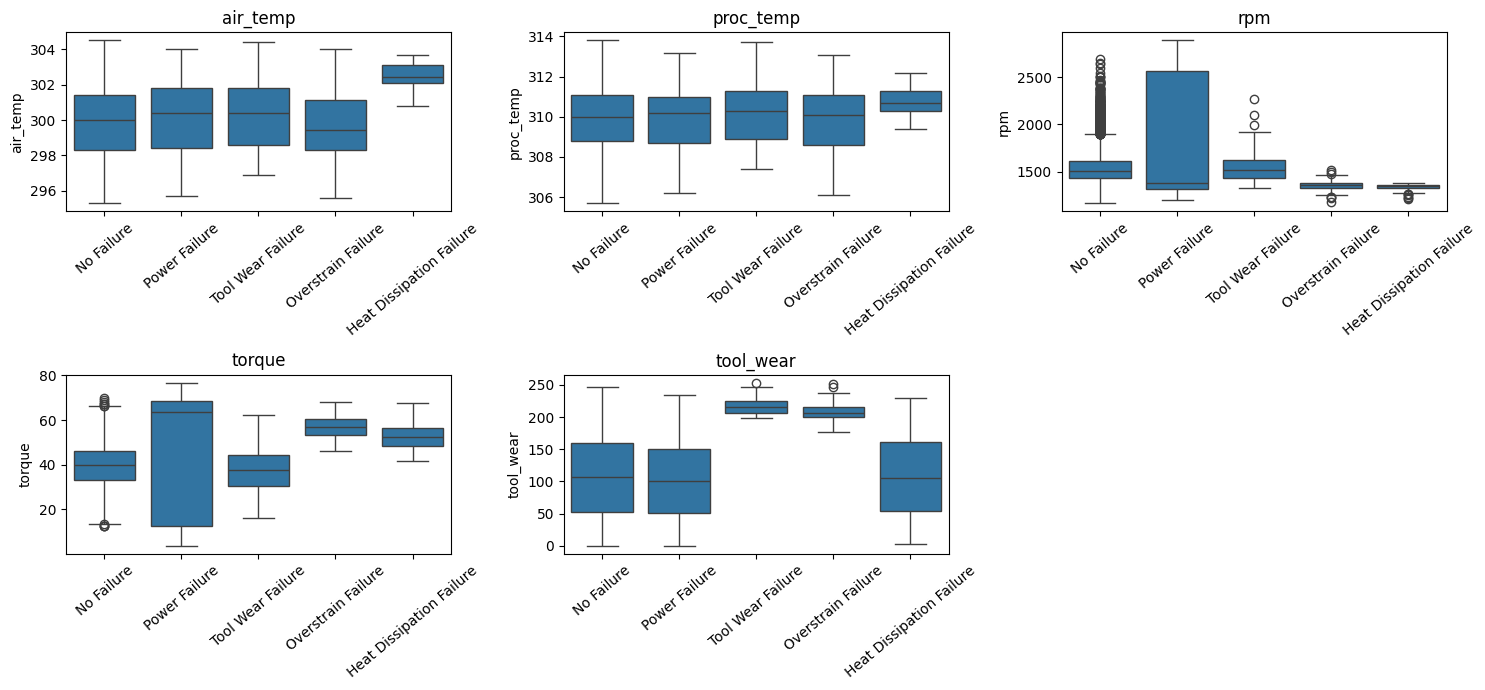

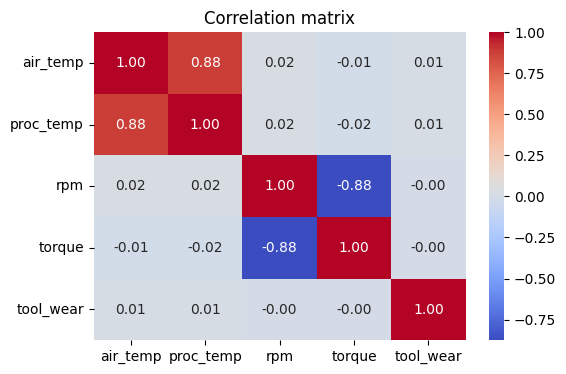

failure,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Tool Wear Failure
Type,,,,,
H,0.0080,0.9800,0.0010,0.0050,0.0060
L,0.0124,0.9614,0.0122,0.0099,0.0042
M,0.0100,0.9736,0.0013,0.0104,0.0047


In [18]:
num_cols = ["air_temp", "proc_temp", "rpm", "torque", "tool_wear"]

# 1) Class distribution (log scale because of the imbalance)
ax = cdf["failure"].value_counts().plot(kind="bar", figsize=(7, 3), logy=True)
ax.set_title("Class distribution (log scale)"); plt.xticks(rotation=30, ha="right"); plt.show()

# 2) Feature distributions
cdf[num_cols].hist(bins=40, figsize=(12, 6)); plt.tight_layout(); plt.show()

# 3) Each feature by failure type: shows which features separate which classes
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axs.ravel(), num_cols):
    sns.boxplot(data=cdf, x="failure", y=c, ax=ax)
    ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=40)
axs.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

# 4) Correlations
plt.figure(figsize=(6, 4))
sns.heatmap(cdf[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix"); plt.show()

# 5) Product type vs failure
display(pd.crosstab(cdf["Type"], cdf["failure"], normalize="index").round(4))

In [19]:
!pip install -q imbalanced-learn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# Encode target and the Type category
le = LabelEncoder()
cdf["y"] = le.fit_transform(cdf["failure"])
class_names = list(le.classes_)
print(dict(zip(class_names, range(len(class_names)))))
cdf["type_code"] = cdf["Type"].map({"L": 0, "M": 1, "H": 2})
feat_cols = num_cols + ["type_code"]

# 1) Stratified split FIRST (test set keeps the real, imbalanced distribution)
Xtr, Xte, ytr, yte = train_test_split(
    cdf[feat_cols].copy(), cdf["y"], test_size=0.2, stratify=cdf["y"], random_state=42)

# 2) Scale numeric columns: fit on TRAIN only
c_scaler = StandardScaler()
Xtr[num_cols] = c_scaler.fit_transform(Xtr[num_cols])
Xte[num_cols] = c_scaler.transform(Xte[num_cols])

# 3) Balance the TRAIN set only: undersample "No Failure", SMOTENC-oversample the rest
no_fail = int(le.transform(["No Failure"])[0])
sampler = ImbPipeline([
    ("under", RandomUnderSampler(sampling_strategy={no_fail: 2000}, random_state=42)),
    ("smote", SMOTENC(categorical_features=[feat_cols.index("type_code")],
                      k_neighbors=5, random_state=42)),
])
Xtr_bal, ytr_bal = sampler.fit_resample(Xtr.values, ytr.values)

# 4) One-hot encode Type -> final model inputs (5 numeric + 3 one-hot = 8 features)
def to_model_input(X):
    num = X[:, :len(num_cols)]
    onehot = np.eye(3)[X[:, -1].round().astype(int)]
    return np.hstack([num, onehot]).astype("float32")

c_X_train, c_y_train = to_model_input(Xtr_bal), ytr_bal.astype("int64")
c_X_test,  c_y_test  = to_model_input(Xte.values), yte.values.astype("int64")

print("\nTrain before balancing:\n", ytr.map(dict(enumerate(class_names))).value_counts())
print("\nTrain after balancing:\n", pd.Series(c_y_train).map(dict(enumerate(class_names))).value_counts())
print("\nTest (untouched):\n", pd.Series(c_y_test).map(dict(enumerate(class_names))).value_counts())
print(c_X_train.shape, c_X_test.shape)

{'Heat Dissipation Failure': 0, 'No Failure': 1, 'Overstrain Failure': 2, 'Power Failure': 3, 'Tool Wear Failure': 4}

Train before balancing:
 y
No Failure                  7714
Heat Dissipation Failure      90
Power Failure                 76
Overstrain Failure            62
Tool Wear Failure             36
Name: count, dtype: int64

Train after balancing:
 Heat Dissipation Failure    2000
No Failure                  2000
Overstrain Failure          2000
Power Failure               2000
Tool Wear Failure           2000
Name: count, dtype: int64

Test (untouched):
 No Failure                  1929
Heat Dissipation Failure      22
Power Failure                 19
Overstrain Failure            16
Tool Wear Failure              9
Name: count, dtype: int64
(10000, 8) (1995, 8)


In [20]:
from torch.nn import CrossEntropyLoss
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

class ClsDataset(Dataset):
    def __init__(self, X, y):
        self.X = X.astype("float32")
        self.y = y.astype("int64")
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return [self.X[idx], self.y[idx]]

cls_train_dl = DataLoader(ClsDataset(c_X_train, c_y_train), batch_size=64, shuffle=True)
cls_test_dl  = DataLoader(ClsDataset(c_X_test,  c_y_test),  batch_size=512, shuffle=False)

class MLPClassifier(Module):
    def __init__(self, n_inputs, n_classes=5, h1=64, h2=32):
        super().__init__()
        self.hidden1 = Linear(n_inputs, h1)
        kaiming_uniform_(self.hidden1.weight, nonlinearity="relu")
        self.act1 = ReLU()
        self.hidden2 = Linear(h1, h2)
        kaiming_uniform_(self.hidden2.weight, nonlinearity="relu")
        self.act2 = ReLU()
        self.hidden3 = Linear(h2, n_classes)       # raw scores (logits)
        xavier_uniform_(self.hidden3.weight)

    def forward(self, X):
        X = self.act1(self.hidden1(X))
        X = self.act2(self.hidden2(X))
        return self.hidden3(X)

def eval_cls(dl, model):
    model.eval()
    criterion = CrossEntropyLoss(reduction="sum")
    total_loss, preds, actuals = 0.0, [], []
    with torch.no_grad():
        for inputs, targets in dl:
            logits = model(inputs.to(device))
            total_loss += criterion(logits, targets.to(device)).item()
            preds.append(logits.argmax(dim=1).cpu().numpy())
            actuals.append(targets.numpy())
    preds, actuals = np.concatenate(preds), np.concatenate(actuals)
    return total_loss / len(actuals), accuracy_score(actuals, preds), preds, actuals

def train_cls(train_dl, test_dl, model, epochs=50, optimizer_cls=SGD, lr=0.01,
              weight_decay=0.0, l1=0.0, **opt_kwargs):
    model.to(device)
    criterion = CrossEntropyLoss()
    optimizer = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay, **opt_kwargs)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for epoch in tqdm(range(epochs), desc="Training Epochs"):
        model.train()
        for inputs, targets in train_dl:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()                    # clear the gradients
            loss = criterion(model(inputs), targets) # forward + loss
            if l1 > 0:
                loss = loss + l1 * sum(p.abs().sum() for n, p in model.named_parameters() if "weight" in n)
            loss.backward()                          # credit assignment
            optimizer.step()                         # update weights

        tr_loss, tr_acc, _, _ = eval_cls(train_dl, model)
        te_loss, te_acc, _, _ = eval_cls(test_dl, model)
        history["train_loss"].append(tr_loss); history["test_loss"].append(te_loss)
        history["train_acc"].append(tr_acc);   history["test_acc"].append(te_acc)
    return history

Training Epochs: 100%|██████████| 50/50 [00:14<00:00,  3.39it/s]


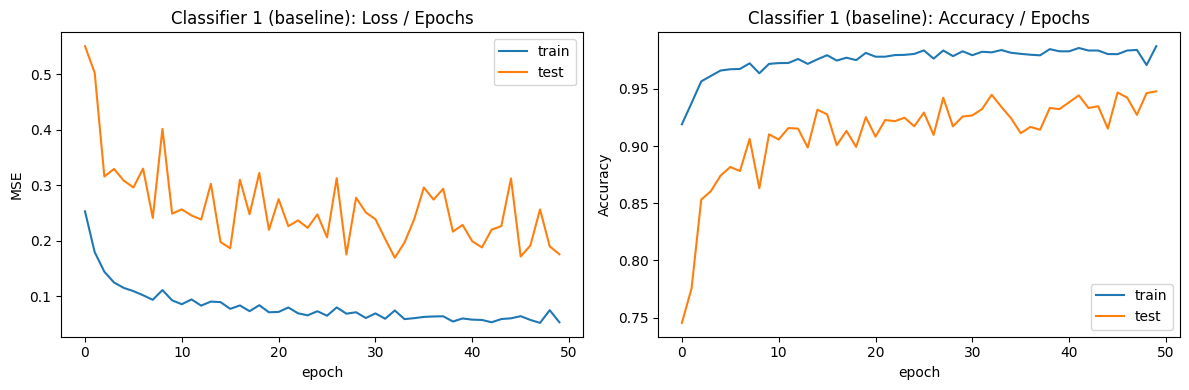

In [21]:
torch.manual_seed(42)
cls_model1 = MLPClassifier(n_inputs=c_X_train.shape[1])
cls_hist1 = train_cls(cls_train_dl, cls_test_dl, cls_model1, epochs=50,
                      optimizer_cls=SGD, lr=0.01, momentum=0.9)   # professor's setup

plot_history(cls_hist1, "Classifier 1 (baseline)", metric="acc", label="Accuracy")


===== Classifier 1 | TRAIN =====
                          precision    recall  f1-score   support

Heat Dissipation Failure      0.991     0.998     0.994      2000
              No Failure      0.993     0.966     0.979      2000
      Overstrain Failure      0.988     0.988     0.988      2000
           Power Failure      0.997     0.999     0.998      2000
       Tool Wear Failure      0.969     0.987     0.978      2000

                accuracy                          0.987     10000
               macro avg      0.987     0.987     0.987     10000
            weighted avg      0.987     0.987     0.987     10000


===== Classifier 1 | TEST =====
                          precision    recall  f1-score   support

Heat Dissipation Failure      0.489     1.000     0.657        22
              No Failure      0.995     0.953     0.973      1929
      Overstrain Failure      0.571     0.750     0.649        16
           Power Failure      0.609     0.737     0.667        19
     

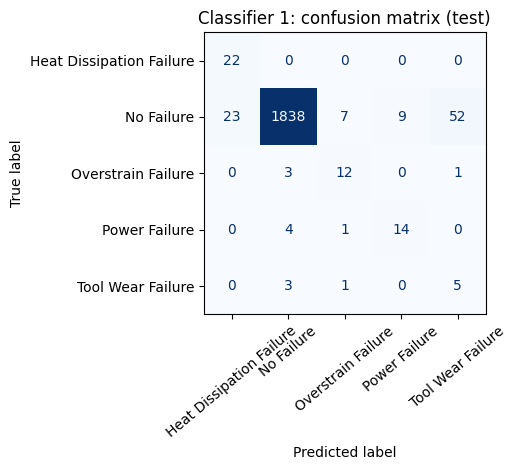

In [22]:
cls_results = []

def cls_metrics(model, name, show_cm=True):
    out = {"model": name}
    for split, dl in [("train", cls_train_dl), ("test", cls_test_dl)]:
        loss, acc, p, a = eval_cls(dl, model)
        out[f"{split}_acc"] = acc
        out[f"{split}_macroF1"] = f1_score(a, p, average="macro", zero_division=0)
        out[f"{split}_macroRecall"] = (confusion_matrix(a, p).diagonal() / np.bincount(a, minlength=5)).mean()
        print(f"\n===== {name} | {split.upper()} =====")
        print(classification_report(a, p, target_names=class_names, digits=3, zero_division=0))
        if show_cm and split == "test":
            ConfusionMatrixDisplay(confusion_matrix(a, p), display_labels=class_names).plot(
                xticks_rotation=40, cmap="Blues", colorbar=False)
            plt.title(f"{name}: confusion matrix (test)"); plt.tight_layout(); plt.show()
    cls_results.append(out)

cls_metrics(cls_model1, "Classifier 1")

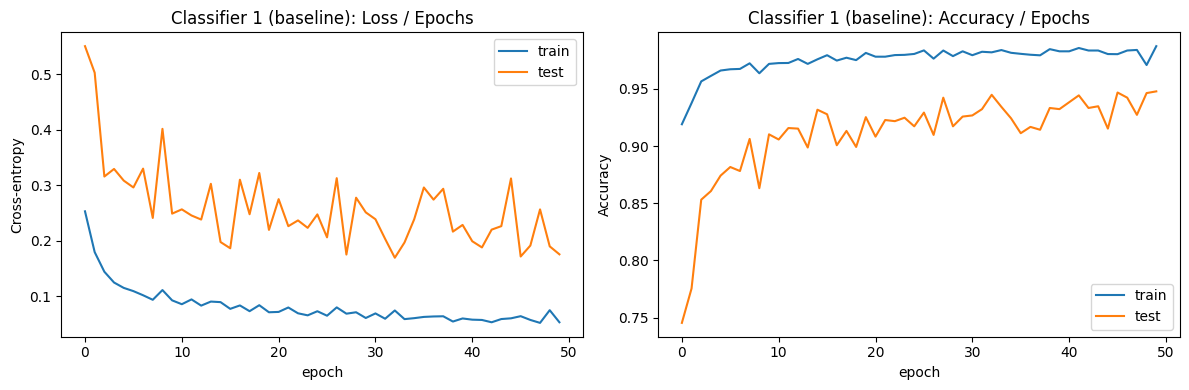

In [23]:
def plot_history(hist, title, metric="r2", label="R²", loss_label="MSE"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title(f"{title}: Loss / Epochs"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel(loss_label); ax[0].legend()
    ax[1].plot(hist[f"train_{metric}"], label="train"); ax[1].plot(hist[f"test_{metric}"], label="test")
    ax[1].set_title(f"{title}: {label} / Epochs"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel(label); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(cls_hist1, "Classifier 1 (baseline)", metric="acc", label="Accuracy", loss_label="Cross-entropy")

In [24]:
from skorch import NeuralNetClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import StratifiedKFold

torch.manual_seed(42); np.random.seed(42)

net_c = NeuralNetClassifier(
    module=MLPClassifier,
    module__n_inputs=8,
    criterion=CrossEntropyLoss,        # module outputs raw logits
    batch_size=64,
    train_split=None,
    device=device,
    verbose=0,
)

pipe = ImbPipeline([
    ("under", RandomUnderSampler(sampling_strategy={no_fail: 2000}, random_state=42)),
    ("smote", SMOTENC(categorical_features=[feat_cols.index("type_code")], k_neighbors=3, random_state=42)),
    ("onehot", FunctionTransformer(to_model_input)),
    ("net", net_c),
])

common = {
    "net__lr": [0.001, 0.01],
    "net__max_epochs": [20, 50],
    "net__module__h1": [32, 128],
}
param_grid = [
    {"net__optimizer": [SGD],  "net__optimizer__momentum": [0.9], **common},
    {"net__optimizer": [Adam], **common},
]   # 16 combinations x 3 folds = 48 fits

gs_c = GridSearchCV(pipe, param_grid, scoring="f1_macro",
                    cv=StratifiedKFold(3, shuffle=True, random_state=42),
                    refit=False, n_jobs=1, verbose=1)
gs_c.fit(Xtr.values.astype("float64"), ytr.values.astype("int64"))

print("Best params:", gs_c.best_params_)
print("Best CV macro-F1: %.4f" % gs_c.best_score_)

res_c = pd.DataFrame(gs_c.cv_results_)
res_c["optimizer"] = res_c["param_net__optimizer"].apply(lambda o: o.__name__)
display(res_c[["optimizer", "param_net__lr", "param_net__max_epochs", "param_net__module__h1",
               "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best params: {'net__lr': 0.001, 'net__max_epochs': 50, 'net__module__h1': 128, 'net__optimizer': <class 'torch.optim.adam.Adam'>}
Best CV macro-F1: 0.4354


,optimizer,param_net__lr,param_net__max_epochs,param_net__module__h1,mean_test_score,std_test_score
11,Adam,0.001,50,128,0.435430,0.018082
10,Adam,0.001,50,32,0.420890,0.022005
6,SGD,0.010,50,32,0.412474,0.015899
2,SGD,0.001,50,32,0.409915,0.010398
3,SGD,0.001,50,128,0.398822,0.005604
7,SGD,0.010,50,128,0.388350,0.056609
15,Adam,0.010,50,128,0.371747,0.048958
14,Adam,0.010,50,32,0.363865,0.042291
9,Adam,0.001,20,128,0.346595,0.008638
8,Adam,0.001,20,32,0.333995,0.016820


Training Epochs: 100%|██████████| 50/50 [00:18<00:00,  2.68it/s]


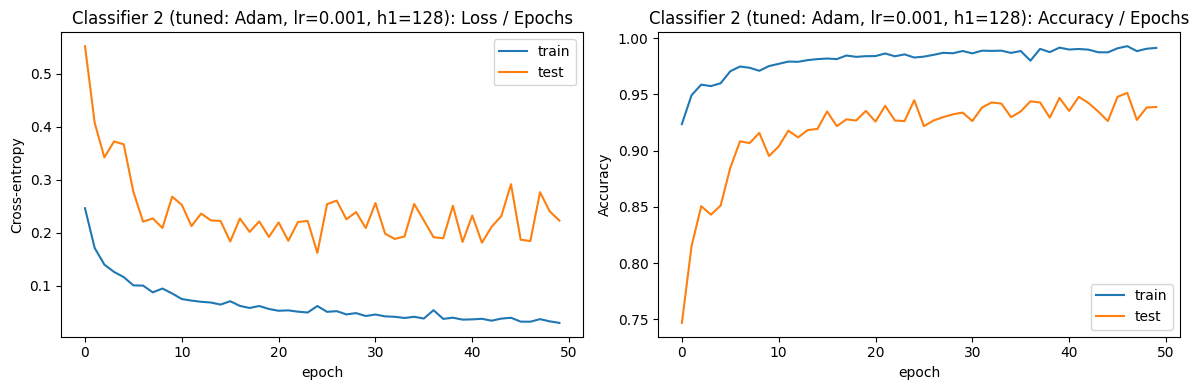


===== Classifier 2 (tuned) | TRAIN =====
                          precision    recall  f1-score   support

Heat Dissipation Failure      0.994     1.000     0.997      2000
              No Failure      1.000     0.961     0.980      2000
      Overstrain Failure      0.994     0.999     0.996      2000
           Power Failure      0.995     1.000     0.997      2000
       Tool Wear Failure      0.976     0.999     0.987      2000

                accuracy                          0.991     10000
               macro avg      0.992     0.991     0.991     10000
            weighted avg      0.992     0.991     0.991     10000


===== Classifier 2 (tuned) | TEST =====
                          precision    recall  f1-score   support

Heat Dissipation Failure      0.478     1.000     0.647        22
              No Failure      0.997     0.941     0.968      1929
      Overstrain Failure      0.452     0.875     0.596        16
           Power Failure      0.552     0.842     0.667

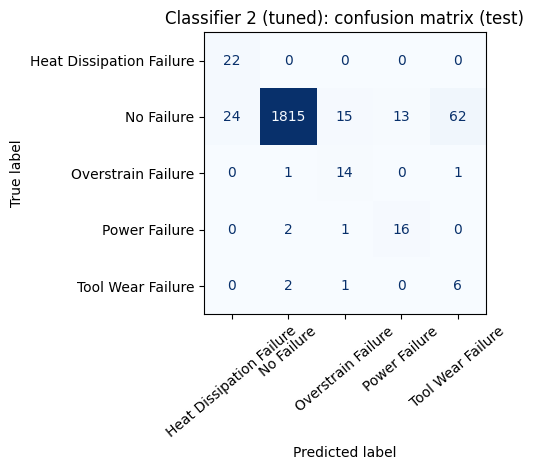

,model,train_acc,train_macroF1,train_macroRecall,test_acc,test_macroF1,test_macroRecall
0,Classifier 1,0.9874,0.9874,0.9874,0.9479,0.6189,0.7990
1,Classifier 2 (tuned),0.9914,0.9914,0.9914,0.9388,0.6063,0.8649


In [25]:
torch.manual_seed(42)
cls_model2 = MLPClassifier(n_inputs=c_X_train.shape[1], h1=128, h2=32)
cls_hist2 = train_cls(cls_train_dl, cls_test_dl, cls_model2, epochs=50,
                      optimizer_cls=Adam, lr=0.001)

plot_history(cls_hist2, "Classifier 2 (tuned: Adam, lr=0.001, h1=128)",
             metric="acc", label="Accuracy", loss_label="Cross-entropy")
cls_metrics(cls_model2, "Classifier 2 (tuned)")

display(pd.DataFrame(cls_results).round(4))

In [26]:
_, _, p2, a2 = eval_cls(cls_test_dl, cls_model2)
tw = class_names.index("Tool Wear Failure")
raw = c_scaler.inverse_transform(Xte[num_cols].values)     # back to original units
tool_wear_raw = raw[:, num_cols.index("tool_wear")]

groups = {
    "healthy, predicted Tool Wear (false alarms)": (a2 == no_fail) & (p2 == tw),
    "real Tool Wear failures":                     (a2 == tw),
    "healthy, predicted healthy":                  (a2 == no_fail) & (p2 == no_fail),
}
for name, m in groups.items():
    print(f"{name:45s} n={m.sum():4d}  tool_wear: mean={tool_wear_raw[m].mean():6.1f}  min={tool_wear_raw[m].min():5.1f}")

healthy, predicted Tool Wear (false alarms)   n=  62  tool_wear: mean= 212.5  min=186.0
real Tool Wear failures                       n=   9  tool_wear: mean= 214.1  min=203.0
healthy, predicted healthy                    n=1815  tool_wear: mean= 104.9  min=  0.0


In [27]:
import copy
from torch.nn import Dropout

# --- validation split for early stopping: BEFORE balancing ---
Xsub, Xval, ysub, yval = train_test_split(Xtr, ytr, test_size=0.2, stratify=ytr, random_state=42)
Xsub_bal, ysub_bal = sampler.fit_resample(Xsub.values, ysub.values)
cls_es_train_dl = DataLoader(ClsDataset(to_model_input(Xsub_bal), ysub_bal.astype("int64")),
                             batch_size=64, shuffle=True)
cls_val_dl = DataLoader(ClsDataset(to_model_input(Xval.values), yval.values.astype("int64")),
                        batch_size=512)

class MLPClassifierDrop(Module):
    def __init__(self, n_inputs, n_classes=5, h1=128, h2=32, p=0.2):
        super().__init__()
        self.hidden1 = Linear(n_inputs, h1); kaiming_uniform_(self.hidden1.weight, nonlinearity="relu")
        self.act1 = ReLU(); self.drop1 = Dropout(p)
        self.hidden2 = Linear(h1, h2); kaiming_uniform_(self.hidden2.weight, nonlinearity="relu")
        self.act2 = ReLU(); self.drop2 = Dropout(p)
        self.hidden3 = Linear(h2, n_classes); xavier_uniform_(self.hidden3.weight)
    def forward(self, X):
        X = self.drop1(self.act1(self.hidden1(X)))
        X = self.drop2(self.act2(self.hidden2(X)))
        return self.hidden3(X)

def train_cls_reg(train_dl, test_dl, model, epochs=50, optimizer_cls=Adam, lr=1e-3,
                  weight_decay=0.0, l1=0.0, val_dl=None, patience=None):
    model.to(device)
    criterion = CrossEntropyLoss()
    optimizer = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    best_f1, best_state, wait = -1.0, None, 0

    for epoch in tqdm(range(epochs), desc="Training Epochs"):
        model.train()
        for inputs, targets in train_dl:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), targets)
            if l1 > 0:
                loss = loss + l1 * sum(p.abs().sum() for n, p in model.named_parameters() if "weight" in n)
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc, _, _ = eval_cls(train_dl, model)
        te_loss, te_acc, _, _ = eval_cls(test_dl, model)
        history["train_loss"].append(tr_loss); history["test_loss"].append(te_loss)
        history["train_acc"].append(tr_acc);   history["test_acc"].append(te_acc)

        if val_dl is not None and patience:       # early stopping on validation macro-F1
            _, _, vp, va = eval_cls(val_dl, model)
            vf1 = f1_score(va, vp, average="macro", zero_division=0)
            if vf1 > best_f1 + 1e-4:
                best_f1, best_state, wait = vf1, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping at epoch {epoch+1} (best val macro-F1 = {best_f1:.3f})"); break
    if best_state is not None:
        model.load_state_dict(best_state)
    return history

def cls_row(model, name):
    out = {"model": name}
    for split, dl in [("train", cls_train_dl), ("test", cls_test_dl)]:
        _, acc, p, a = eval_cls(dl, model)
        out[f"{split}_acc"] = acc
        out[f"{split}_macroF1"] = f1_score(a, p, average="macro", zero_division=0)
        out[f"{split}_macroRecall"] = (confusion_matrix(a, p).diagonal() / np.bincount(a, minlength=5)).mean()
    healthy = (a == no_fail)                                   # a, p = test labels/predictions here
    out["test_false_alarm"] = (p[healthy] != no_fail).mean()   # healthy flagged as failure
    out["test_missed"] = (p[~healthy] == no_fail).mean()       # failures called healthy
    return out

Training Epochs:  53%|█████▎    | 53/100 [00:15<00:13,  3.41it/s]

Early stopping at epoch 54 (best val macro-F1 = 0.709)


,model,train_acc,train_macroF1,train_macroRecall,test_acc,test_macroF1,test_macroRecall,test_false_alarm,test_missed
8,Early stopping (patience=10),0.9694,0.9694,0.9694,0.9424,0.6434,0.8428,0.0544,0.1212
4,L1 (1e-5),0.9895,0.9895,0.9895,0.9429,0.6244,0.8782,0.0555,0.0758
0,Classifier 1 (baseline),0.9874,0.9874,0.9874,0.9479,0.6189,0.7990,0.0472,0.1515
1,"Classifier 2 (tuned, no reg.)",0.9914,0.9914,0.9914,0.9388,0.6063,0.8649,0.0591,0.0758
5,Dropout (p=0.2),0.9832,0.9830,0.9832,0.9183,0.5999,0.8815,0.0814,0.0455
2,L2 (wd=1e-4),0.9895,0.9895,0.9895,0.9338,0.5983,0.8418,0.0638,0.0909
7,Dropout 0.2 + L2 1e-4,0.9835,0.9834,0.9835,0.9188,0.5977,0.8712,0.0804,0.0606
3,L2 (wd=1e-3),0.9841,0.9840,0.9841,0.9243,0.5769,0.8743,0.0747,0.0606
6,Dropout (p=0.4),0.9740,0.9737,0.9740,0.8937,0.5612,0.9090,0.1078,0.0152


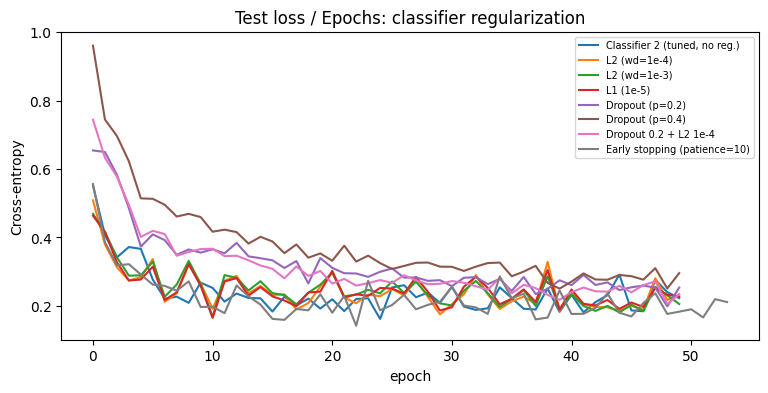

In [28]:
cls_histories = {"Classifier 2 (tuned, no reg.)": cls_hist2}
cls_rows = [cls_row(cls_model1, "Classifier 1 (baseline)"),
            cls_row(cls_model2, "Classifier 2 (tuned, no reg.)")]

def run_cls(name, model, **kw):
    torch.manual_seed(42)
    dl = kw.pop("dl", cls_train_dl)
    cls_histories[name] = train_cls_reg(dl, cls_test_dl, model, **kw)
    cls_rows.append(cls_row(model, name))

mk = lambda: MLPClassifier(n_inputs=8, h1=128, h2=32)

run_cls("L2 (wd=1e-4)", mk(), weight_decay=1e-4)
run_cls("L2 (wd=1e-3)", mk(), weight_decay=1e-3)
run_cls("L1 (1e-5)",    mk(), l1=1e-5)
run_cls("Dropout (p=0.2)", MLPClassifierDrop(8, p=0.2))
run_cls("Dropout (p=0.4)", MLPClassifierDrop(8, p=0.4))
run_cls("Dropout 0.2 + L2 1e-4", MLPClassifierDrop(8, p=0.2), weight_decay=1e-4)
run_cls("Early stopping (patience=10)", mk(), dl=cls_es_train_dl, epochs=100,
        val_dl=cls_val_dl, patience=10)

summary = pd.DataFrame(cls_rows).round(4)
display(summary.sort_values("test_macroF1", ascending=False))

# Overlay of test loss
plt.figure(figsize=(9, 4))
for name, h in cls_histories.items():
    plt.plot(h["test_loss"], label=name)
plt.title("Test loss / Epochs: classifier regularization")
plt.xlabel("epoch"); plt.ylabel("Cross-entropy"); plt.legend(fontsize=7); plt.show()

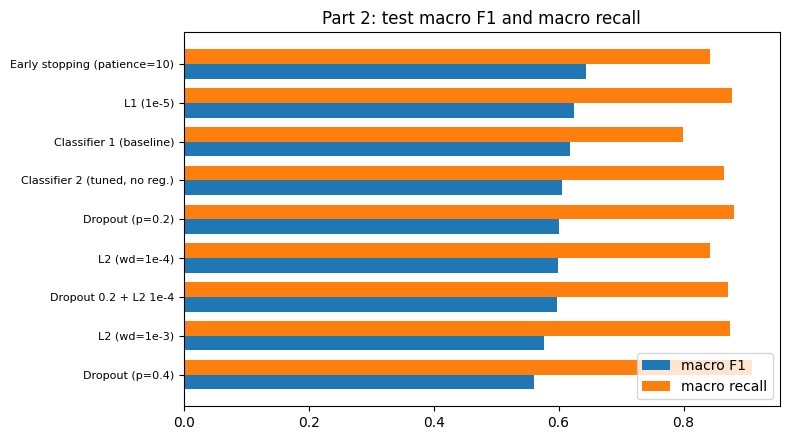

In [29]:
import os
os.makedirs("results", exist_ok=True)

summary.to_csv("results/part2_classifier_comparison.csv", index=False)
pd.DataFrame(results).to_csv("results/part1_regression_comparison.csv", index=False)

# Bar chart for the README
s = summary.sort_values("test_macroF1")
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(s)); h = 0.38
ax.barh(y - h/2, s["test_macroF1"],     h, label="macro F1")
ax.barh(y + h/2, s["test_macroRecall"], h, label="macro recall")
ax.set_yticks(y); ax.set_yticklabels(s["model"], fontsize=8)
ax.set_title("Part 2: test macro F1 and macro recall"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("results/part2_comparison.png", dpi=150); plt.show()

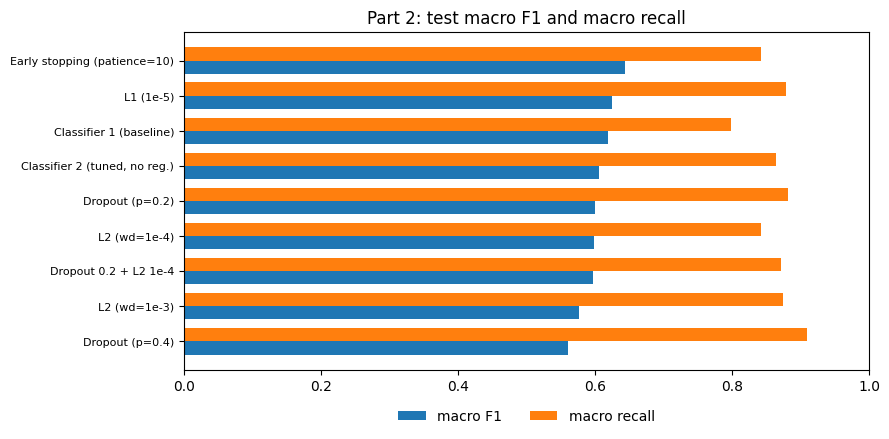

In [30]:
s = summary.sort_values("test_macroF1")
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(s)); h = 0.38
ax.barh(y - h/2, s["test_macroF1"],     h, label="macro F1")
ax.barh(y + h/2, s["test_macroRecall"], h, label="macro recall")
ax.set_yticks(y); ax.set_yticklabels(s["model"], fontsize=8)
ax.set_xlim(0, 1)
ax.set_title("Part 2: test macro F1 and macro recall")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig("results/part2_comparison.png", dpi=150, bbox_inches="tight"); plt.show()